# CAP182 SS3 – Part B: STADIOcare 30-Day Readmission Prediction

**Project objective:** Predict whether an inpatient admission will be followed by a readmission within 30 days.  
**Final method carried forward from SS2:** Logistic Regression (provisional selection).  
**Prediction point:** At or before discharge.  
**Dataset status:** The supplied project README explicitly identifies this as synthetic capstone data, not real STADIOcare patient data.

## Method summary
The Logistic Regression algorithm selected provisionally in SS2 is retained and retrained on the STADIOcare project dataset. The SS2 UCI Diabetes dataset has a different feature structure, so its fitted coefficients cannot be transferred. The algorithm and modelling approach are carried forward, while preprocessing is fitted afresh using the client-supplied project data.

The notebook covers the five assessed components: dataset loading, preprocessing, model training, unseen-data validation and results visualisation.

## 1. Dataset loading and profiling

Place the four CSV files in a local `data/` folder beside this notebook. The data files are intentionally excluded from the GitHub submission package; include them only if the assignment/client explicitly authorises publication.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, roc_curve,
    precision_recall_curve
)

RANDOM_STATE = 42
DATA_DIR = Path("data")
if not DATA_DIR.exists() and Path("/mnt/data/table1_admissions_adt.csv").exists():
    DATA_DIR = Path("/mnt/data")

filenames = {
    "adt": "table1_admissions_adt.csv",
    "clinical": "table2_patient_clinical.csv",
    "utilisation": "table3_previous_utilisation.csv",
    "outcome": "table4_discharge_readmission_outcome.csv"
}
tables = {k: pd.read_csv(DATA_DIR / v) for k, v in filenames.items()}
for name, frame in tables.items():
    print(f"{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")

adt: 7,245 rows × 16 columns
clinical: 6,026 rows × 13 columns
utilisation: 6,026 rows × 7 columns
outcome: 6,026 rows × 10 columns


In [2]:
# Remove exact duplicate rows and report the number removed.
for name in tables:
    before = len(tables[name])
    tables[name] = tables[name].drop_duplicates().copy()
    print(f"{name}: {before - len(tables[name])} exact duplicates removed; "
          f"{len(tables[name]):,} rows retained")

adt = tables["adt"].copy()
clinical = tables["clinical"].copy()
utilisation = tables["utilisation"].copy()
outcome = tables["outcome"].copy()

# Table 1 contains index admissions and subsequent readmission episodes.
# Retain only admissions represented in Table 4 (the index-admission outcome table).
index_admission_ids = outcome["admission_id"].dropna().unique()
adt_index = adt[adt["admission_id"].isin(index_admission_ids)].copy()

# Check key uniqueness before joining.
assert outcome["admission_id"].is_unique
assert adt_index["admission_id"].is_unique
assert clinical["patient_id"].is_unique
assert utilisation["patient_id"].is_unique

# Check patient_id agreement for each admission_id.
key_check = outcome[["admission_id", "patient_id"]].merge(
    adt_index[["admission_id", "patient_id"]],
    on="admission_id", how="left", suffixes=("_outcome", "_adt")
)
assert key_check["patient_id_adt"].notna().all()
assert (key_check["patient_id_outcome"] == key_check["patient_id_adt"]).all()

# Join using the verified keys; validate expected relationship cardinality.
df = outcome.merge(
    adt_index, on=["admission_id", "patient_id"],
    how="inner", validate="one_to_one"
)
df = df.merge(clinical, on="patient_id", how="left", validate="many_to_one")
df = df.merge(utilisation, on="patient_id", how="left", validate="many_to_one")

print("Final modelling table:", df.shape)
print("Unique index admissions:", df["admission_id"].nunique())
print("Unique patients:", df["patient_id"].nunique())

adt: 32 exact duplicates removed; 7,213 rows retained
clinical: 26 exact duplicates removed; 6,000 rows retained
utilisation: 26 exact duplicates removed; 6,000 rows retained
outcome: 26 exact duplicates removed; 6,000 rows retained
Final modelling table: (6000, 42)
Unique index admissions: 6000
Unique patients: 6000


### Target distribution and class imbalance

The target is `readmission_within_30_days`. The outcome is imbalanced, so accuracy is not sufficient on its own. Recall, precision, F1, F2, ROC-AUC and average precision are reported.

,Outcome,Count,Percentage
0,No readmission within 30 days (0),4787,79.783333
1,Readmission within 30 days (1),1213,20.216667


Instances: 6,000; classes: 2; positive prevalence: 20.22%


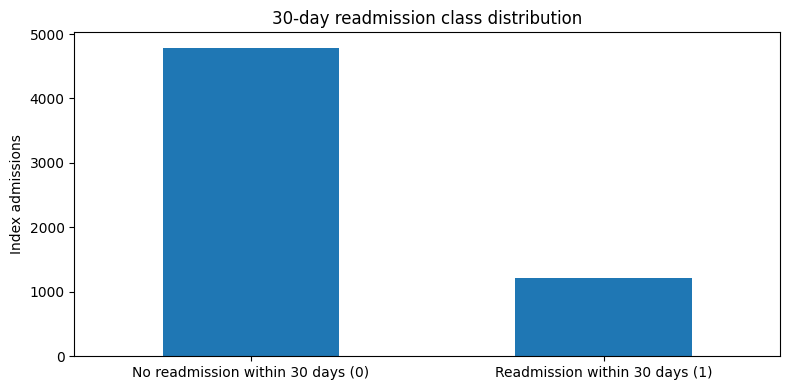

In [3]:
target = "readmission_within_30_days"
if df[target].isna().any():
    raise ValueError("Target contains missing values.")
y = df[target].astype(int)

class_counts = y.value_counts().sort_index()
class_summary = pd.DataFrame({
    "Outcome": ["No readmission within 30 days (0)", "Readmission within 30 days (1)"],
    "Count": [int(class_counts.get(0, 0)), int(class_counts.get(1, 0))]
})
class_summary["Percentage"] = class_summary["Count"] / len(df) * 100
display(class_summary)
print(f"Instances: {len(df):,}; classes: {y.nunique()}; positive prevalence: {y.mean():.2%}")

ax = class_summary.set_index("Outcome")["Count"].plot(kind="bar", figsize=(8,4), rot=0)
ax.set_title("30-day readmission class distribution")
ax.set_ylabel("Index admissions")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 2. Preprocessing and data splitting

### Data preparation
- Remove exact duplicate records.
- Standardise whitespace and common sex-value variants.
- Parse admission date and derive admission month.
- Set implausible numeric values to missing (for example, negative length of stay, age outside 1–120, or ICU days exceeding length of stay).
- Use median imputation for numeric fields and most-frequent imputation for categorical fields, fitted only on training data.
- One-hot encode categorical predictors and standardise numeric predictors.

### Leakage controls
The target, readmission date and readmission diagnosis are excluded. Post-discharge follow-up attendance and home/virtual follow-up are excluded because they occur after the prediction point. Discharge planning outcome-table fields are excluded from this baseline. Patient/admission identifiers, raw dates and free-text clinical notes are also excluded.

### Split
A grouped 70% training, 15% validation and 15% test split is used. Patient groups are kept separate. The validation set is used to choose a recall-weighted threshold; the test set is used once for final evaluation.

In [4]:
# Clean and standardise fields.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].map(lambda v: v.strip() if isinstance(v, str) else v)

# Standardise sex variants.
if "sex" in df.columns:
    df["sex"] = df["sex"].str.lower().replace({"f": "female", "m": "male"})

df["admission_date"] = pd.to_datetime(
    df["admission_date"], errors="coerce", format="mixed", dayfirst=True
)
df["admission_month"] = df["admission_date"].dt.month.astype("Int64").astype("string")

# Exclude IDs, target/outcome-only fields, post-discharge fields, text and raw dates.
exclude = [
    "patient_id", "admission_id", "readmission_within_30_days",
    "readmission_date", "readmission_diagnosis", "follow_up_attendance",
    "home_virtual_follow_up", "follow_up_required", "follow_up_appointment_date",
    "discharge_destination", "discharge_status", "clinical_notes",
    "admission_date", "discharge_date"
]
feature_cols = [c for c in df.columns if c not in exclude]
X = df[feature_cols].copy()
groups = df["patient_id"].copy()

# Convert boolean predictors to categorical labels for consistent preprocessing.
for col in X.columns:
    if X[col].dtype == bool:
        X[col] = X[col].map({True: "true", False: "false"}).astype("object")

numeric_candidates = [
    "age", "length_of_stay", "icu_days", "secondary_diagnosis_count",
    "comorbidity_count", "medication_count", "previous_admission_count",
    "previous_readmission_count", "previous_ed_visits",
    "previous_hospital_days", "days_since_previous_admission",
    "primary_care_visits"
]
for col in numeric_candidates:
    if col in X.columns:
        X[col] = pd.to_numeric(X[col], errors="coerce")
        X.loc[X[col] < 0, col] = np.nan

if "age" in X.columns:
    X.loc[(X["age"] <= 0) | (X["age"] > 120), "age"] = np.nan
if {"icu_days", "length_of_stay"}.issubset(X.columns):
    X.loc[X["icu_days"] > X["length_of_stay"], "icu_days"] = np.nan

# Remove predictors that are entirely missing.
X = X.dropna(axis=1, how="all")

# Grouped 70/30 split, then split the remaining 30% equally into validation and test.
split_1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, temp_idx = next(split_1.split(X, y, groups=groups))
X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_temp, y_temp, g_temp = X.iloc[temp_idx], y.iloc[temp_idx], groups.iloc[temp_idx]

split_2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_STATE)
val_rel, test_rel = next(split_2.split(X_temp, y_temp, groups=g_temp))
X_val, y_val, g_val = X_temp.iloc[val_rel], y_temp.iloc[val_rel], g_temp.iloc[val_rel]
X_test, y_test, g_test = X_temp.iloc[test_rel], y_temp.iloc[test_rel], g_temp.iloc[test_rel]

assert set(g_train).isdisjoint(set(g_val))
assert set(g_train).isdisjoint(set(g_test))
assert set(g_val).isdisjoint(set(g_test))

split_table = pd.DataFrame({
    "Partition": ["Training", "Validation", "Test"],
    "Records": [len(X_train), len(X_val), len(X_test)],
    "Positive class rate": [y_train.mean(), y_val.mean(), y_test.mean()],
    "Unique patients": [g_train.nunique(), g_val.nunique(), g_test.nunique()]
})
display(split_table)

,Partition,Records,Positive class rate,Unique patients
0,Training,4200,0.202143,4200
1,Validation,900,0.201111,900
2,Test,900,0.203333,900


In [5]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)
print("Preprocessing is fitted within the model pipeline using training data only.")

Numeric predictors: ['secondary_diagnosis_count', 'length_of_stay', 'icu_days', 'age', 'comorbidity_count', 'medication_count', 'previous_admission_count', 'previous_readmission_count', 'previous_ed_visits', 'previous_hospital_days', 'days_since_previous_admission', 'primary_care_visits']
Categorical predictors: ['hospital_id', 'admission_type', 'admission_source', 'ward', 'department', 'diagnosis_code', 'procedure_code', 'icu_admission', 'sex', 'province', 'diabetes', 'hypertension', 'cardiovascular_disease', 'chronic_respiratory_disease', 'renal_disease', 'mental_health_condition', 'admission_month']
Preprocessing is fitted within the model pipeline using training data only.


## 3. Model training and hyperparameter justification

Logistic Regression is retained as the provisional final algorithm from SS2. In SS2, it achieved higher recall than Random Forest, which is relevant where missed readmissions are a concern. Logistic Regression also offers a comparatively interpretable baseline.

The algorithm is retrained on this dataset because the SS2 UCI dataset and STADIOcare project dataset contain different feature columns. The selected settings are `class_weight='balanced'` to address class imbalance, `max_iter=1500` to support convergence, `solver='liblinear'` for binary classification and `random_state=42` for reproducibility.

In [6]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])
model.fit(X_train, y_train)
train_prob = model.predict_proba(X_train)[:, 1]
val_prob = model.predict_proba(X_val)[:, 1]
print("Logistic Regression model fitted.")
print("Training records:", len(X_train), "| Validation records:", len(X_val))

Logistic Regression model fitted.
Training records: 4200 | Validation records: 900


## 4. Model validation on unseen data

The validation partition selects a probability threshold by maximising F2-score. F2 weights recall more heavily than precision, reflecting a screening objective in which missing a patient who is subsequently readmitted may be costly. The threshold is a modelling choice for evaluation, not a clinical decision rule.

The selected threshold is then locked and applied to the untouched test partition.

Selected validation threshold: 0.33
Validation F2 at selected threshold: 0.572


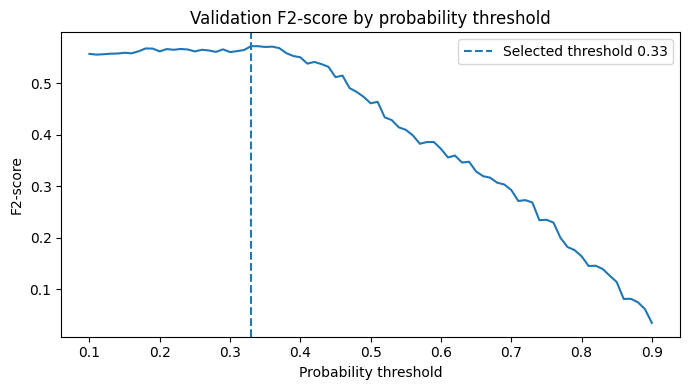

In [7]:
thresholds = np.linspace(0.10, 0.90, 81)
validation_f2 = [
    fbeta_score(y_val, (val_prob >= threshold).astype(int), beta=2, zero_division=0)
    for threshold in thresholds
]
best_threshold = float(thresholds[int(np.argmax(validation_f2))])
print(f"Selected validation threshold: {best_threshold:.2f}")
print(f"Validation F2 at selected threshold: {max(validation_f2):.3f}")

plt.figure(figsize=(7,4))
plt.plot(thresholds, validation_f2)
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold {best_threshold:.2f}")
plt.title("Validation F2-score by probability threshold")
plt.xlabel("Probability threshold")
plt.ylabel("F2-score")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

def metric_row(y_true, probabilities, threshold, name):
    predicted = (probabilities >= threshold).astype(int)
    return {
        "Evaluation": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predicted),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "F2": fbeta_score(y_true, predicted, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average precision": average_precision_score(y_true, probabilities)
    }

test_metrics = pd.DataFrame([
    metric_row(y_test, test_prob, 0.50, "Test – default threshold"),
    metric_row(y_test, test_prob, best_threshold, "Test – validation-selected threshold")
])
display(test_metrics.round(3))
print(classification_report(
    y_test, test_pred,
    target_names=["No readmission", "Readmission"],
    zero_division=0
))

,Evaluation,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average precision
0,Test – default threshold,0.50,0.704,0.35,0.530,0.422,0.481,0.662,0.373
1,Test – validation-selected threshold,0.33,0.492,0.25,0.749,0.375,0.535,0.662,0.373


                precision    recall  f1-score   support

No readmission       0.87      0.43      0.57       717
   Readmission       0.25      0.75      0.37       183

      accuracy                           0.49       900
     macro avg       0.56      0.59      0.47       900
  weighted avg       0.74      0.49      0.53       900



## 5. Results visualisation

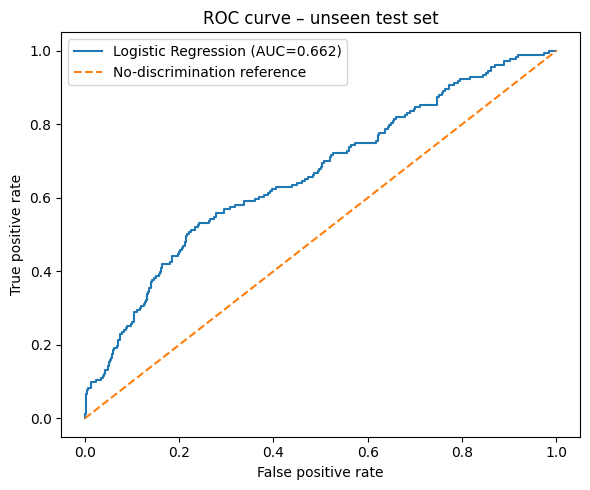

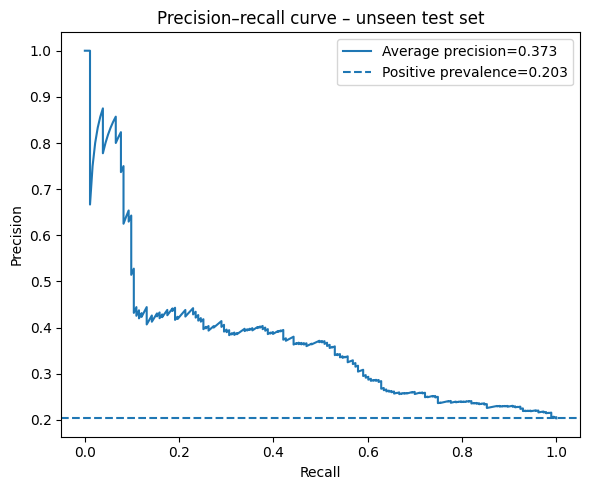

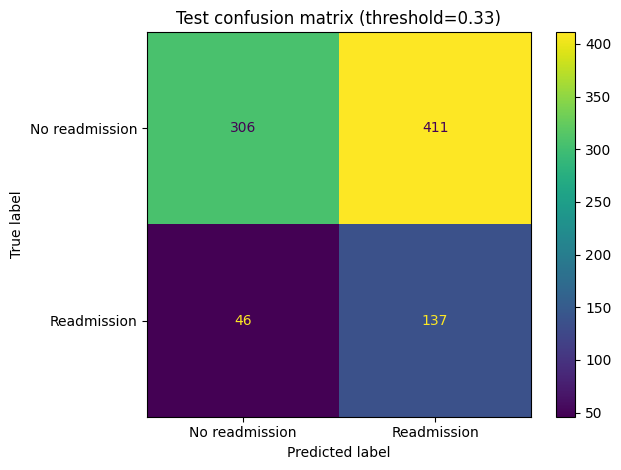

In [9]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, test_prob)
auc = roc_auc_score(y_test, test_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC={auc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="No-discrimination reference")
plt.title("ROC curve – unseen test set")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.tight_layout()
plt.show()

# Precision-recall curve
precision, recall, _ = precision_recall_curve(y_test, test_prob)
ap = average_precision_score(y_test, test_prob)
plt.figure(figsize=(6,5))
plt.plot(recall, precision, label=f"Average precision={ap:.3f}")
plt.axhline(y_test.mean(), linestyle="--", label=f"Positive prevalence={y_test.mean():.3f}")
plt.title("Precision–recall curve – unseen test set")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

# Confusion matrix
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No readmission", "Readmission"]
).plot(values_format="d")
plt.title(f"Test confusion matrix (threshold={best_threshold:.2f})")
plt.tight_layout()
plt.show()

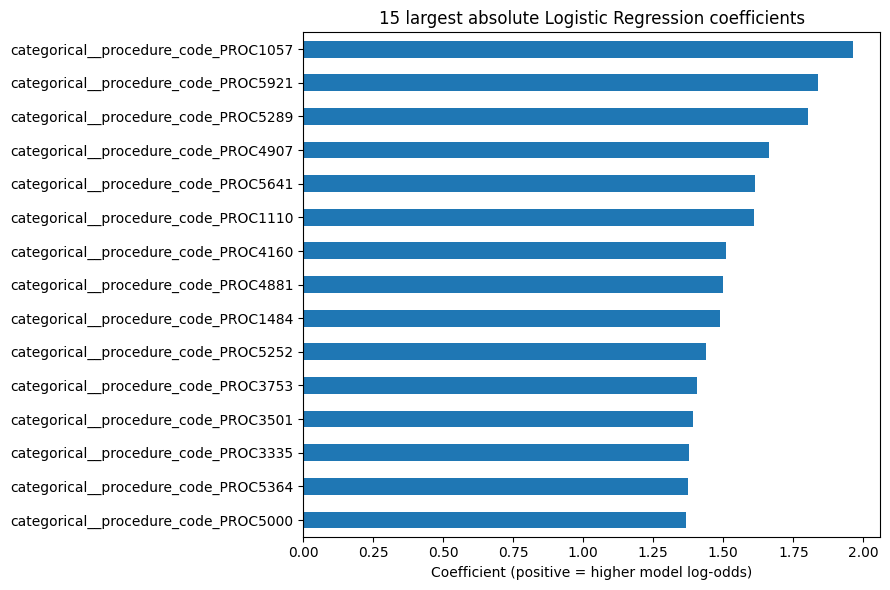

,Coefficient
categorical__procedure_code_PROC5000,1.367922
categorical__procedure_code_PROC5364,1.375631
categorical__procedure_code_PROC3335,1.376314
categorical__procedure_code_PROC3501,1.391234
categorical__procedure_code_PROC3753,1.406500
categorical__procedure_code_PROC5252,1.436863
categorical__procedure_code_PROC1484,1.489782
categorical__procedure_code_PROC4881,1.499089
categorical__procedure_code_PROC4160,1.507864
categorical__procedure_code_PROC1110,1.608841


In [10]:
# Logistic Regression coefficients (directional associations, not causal effects).
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = pd.Series(fitted_classifier.coef_[0], index=feature_names)

top_features = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).head(15).index
).sort_values()
plt.figure(figsize=(9,6))
top_features.plot(kind="barh")
plt.title("15 largest absolute Logistic Regression coefficients")
plt.xlabel("Coefficient (positive = higher model log-odds)")
plt.tight_layout()
plt.show()

display(top_features.rename("Coefficient").to_frame())

## 6. Interpretation, limitations and recommendations

### Interpretation
Use the test-set metrics and plots above to explain performance. Recall measures the proportion of actual readmissions identified. Precision measures the proportion of flagged cases that were readmitted. Average precision summarises the precision–recall trade-off and is useful for an imbalanced outcome. The confusion matrix displays false negatives and false positives at the validation-selected threshold.

### Limitations
1. The supplied README identifies this dataset as synthetic. Results cannot be presented as performance on live STADIOcare patients.
2. A grouped random split reduces patient overlap, but a later time-based holdout would provide a stronger test of future-period generalisation.
3. The model is a baseline; it has not undergone external validation, prospective evaluation or clinical review.
4. The threshold reflects a recall-weighted screening objective and requires agreement with clinical stakeholders.
5. The model identifies associations and risk patterns; it does not establish causation and must not replace clinical judgement.

### Recommendation
Treat the model as a research prototype for decision support only. Before operational use, the client would need to validate it on authorised real-world data, assess calibration and subgroup performance, review false negatives and false positives with clinicians, complete privacy and governance approvals, and monitor performance drift.

In [11]:
# Save reproducible, non-identifying evaluation outputs.
from pathlib import Path
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
test_metrics.to_csv(output_dir / "test_metrics.csv", index=False)

# Aggregate confusion matrix only; no patient-level predictions are exported.
pd.DataFrame(
    cm,
    index=["Actual no readmission", "Actual readmission"],
    columns=["Predicted no readmission", "Predicted readmission"]
).to_csv(output_dir / "test_confusion_matrix.csv")

print("Saved aggregate metrics and confusion matrix to:", output_dir.resolve())
print("Do not export or publish patient-level predictions without explicit authorisation.")

Saved aggregate metrics and confusion matrix to: /mnt/data/outputs
Do not export or publish patient-level predictions without explicit authorisation.


## 7. Reproducibility record

- Algorithm: Logistic Regression
- Random seed: 42
- Split: patient-grouped 70% training / 15% validation / 15% test
- Preprocessing: median/mode imputation, numeric standardisation and one-hot encoding
- Threshold selection: validation F2-score
- Final evaluation: untouched test partition

**Submission check:** Run all cells from top to bottom in a clean kernel. Confirm that the dataset profile, split summary, model outputs, test metrics and plots are visible. Update the project README with the final outputs from your own run.